# Digital Detective: Feature Extraction Challenge
This interactive notebook allows you to run computer vision algorithms (ORB) to extract and match visual features between images, simulating a digital detective searching for clues.

In [20]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Helper function to display images properly in Jupyter/Colab
def show_img(title, img):
    plt.figure(figsize=(12, 8))
    # Convert BGR (OpenCV default) to RGB (Matplotlib default)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    plt.show()

## Step 1: Load and Prepare Images
Make sure you have uploaded `Cup.jpeg` and `Table.jpeg` to your Colab environment or local directory before running this cell.

Images successfully loaded and converted to grayscale.


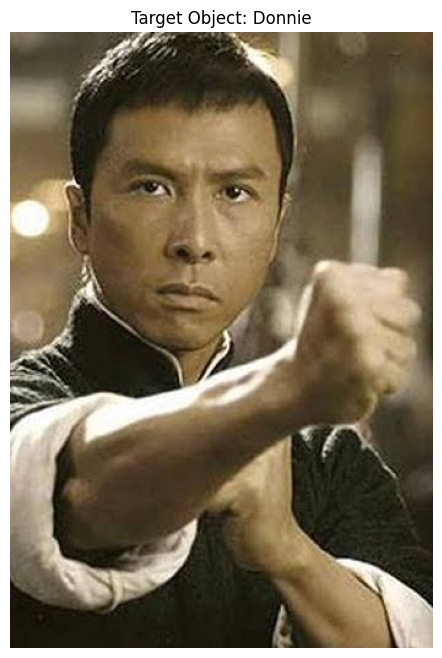

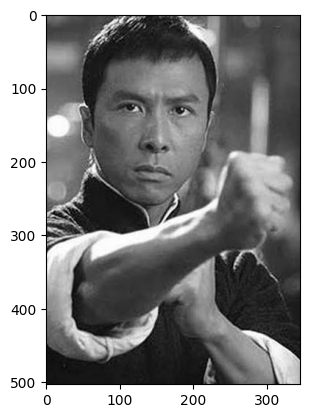

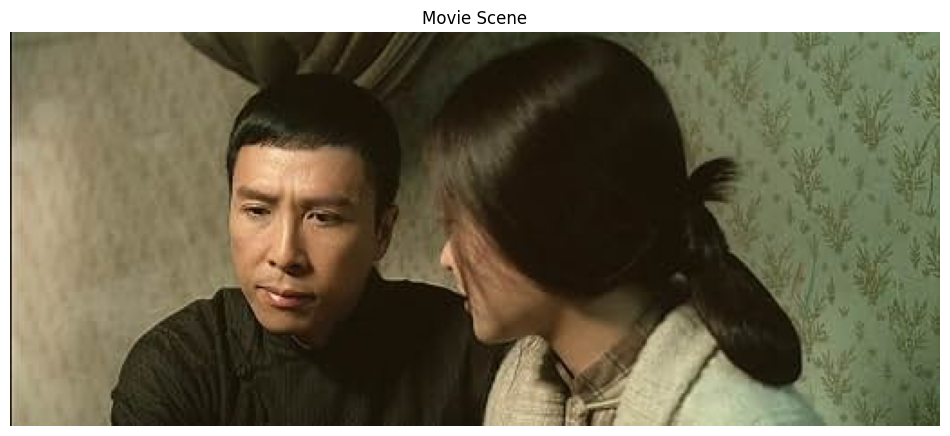

In [28]:
# Load the target image and the scene
img_donnie = cv2.imread('donnie.jpg')
img_yen = cv2.imread('yen.jpg')

if img_donnie is None or img_yen is None:
    print("Error: Could not load images. Please ensure donnie.jpg and yen.jpg are uploaded to the current directory.")
else:
    # Convert to grayscale (feature extraction works best on intensity, not color)
    gray_donnie = cv2.cvtColor(img_donnie, cv2.COLOR_BGR2GRAY)
    gray_yen = cv2.cvtColor(img_yen, cv2.COLOR_BGR2GRAY)
    print("Images successfully loaded and converted to grayscale.")
    show_img("Target Object: Donnie", img_donnie)
    plt.imshow(gray_donnie, cmap='gray')


show_img("Movie Scene", img_yen)

In [22]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **MISSION 1: TRAINING THE COMPUTER**

TOP 5 DISTINCTIVE FEATURES

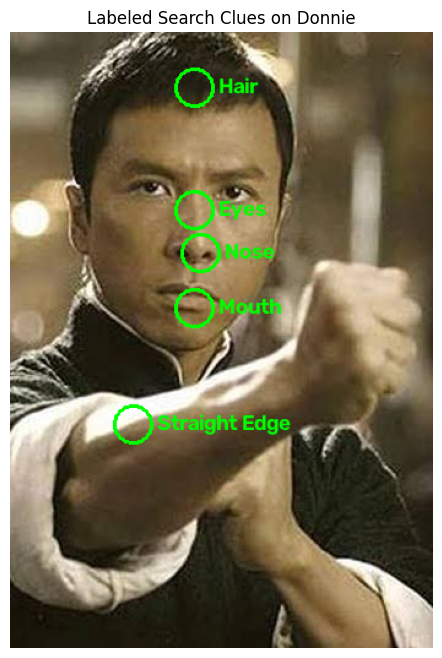

In [29]:
import cv2
import matplotlib.pyplot as plt

# Create a fresh copy of the loaded Donnie image to draw on
annotated_donnie = img_donnie.copy()

# Define target features with coordinates (X, Y) on the 345x503 image
# 1. Eyes (around center of face)
# 2. Hair (top of head)
# 3. Nose (center of face)
# 4. Mouth (below nose)
# 5. Straight Edge (the sharp edge of the white sleeve/arm)

features = {
    "Eyes": (150, 145),
    "Hair": (150, 45),
    "Nose": (155, 180),
    "Mouth": (150, 225),
    "Straight Edge": (100, 320)
}

# Draw circles and label each feature
for label, coord in features.items():
    # Draw a green circle around the target area
    cv2.circle(annotated_donnie, coord, 15, (0, 255, 0), 2)
    # Put text label slightly offset from the circle
    cv2.putText(annotated_donnie, label, (coord[0] + 20, coord[1] + 5),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2, cv2.LINE_AA)

# Display the marked and labeled image
show_img("Labeled Search Clues on Donnie", annotated_donnie)

## Step 2: Extract Features using ORB
Here, the computer acts as the detective, identifying keypoints (distinctive corners and edges) and calculating their mathematical descriptors.

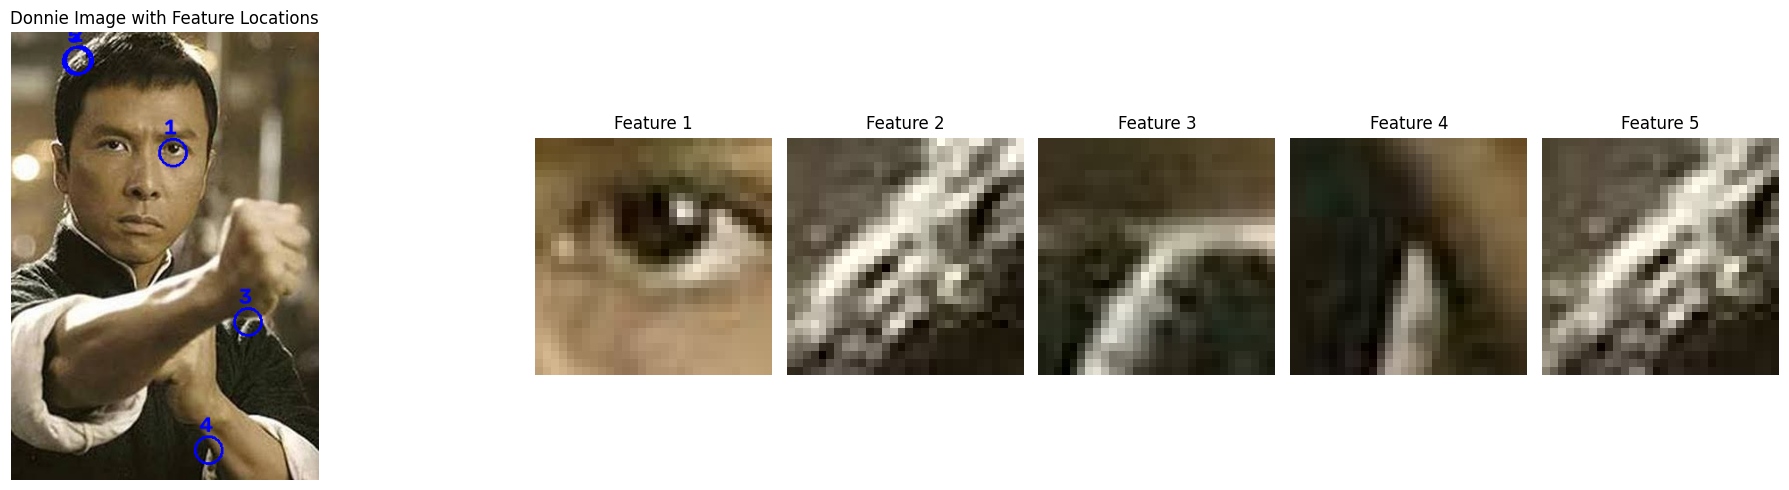

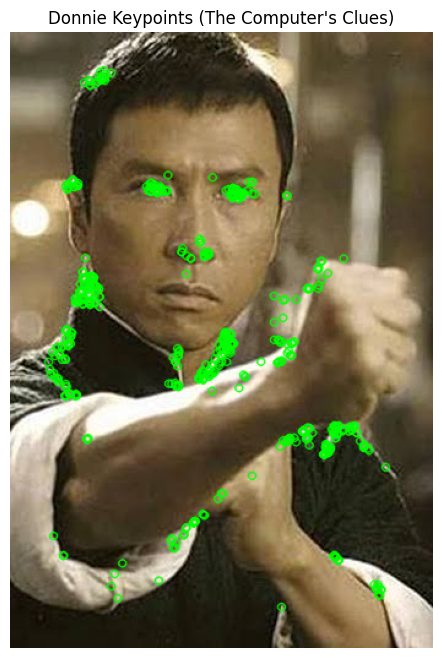

In [26]:
# Initialize the ORB detector (finding up to 500 features)
orb = cv2.ORB_create(nfeatures=500)

# Detect keypoints and compute descriptors
kp_donnie, des_donnie = orb.detectAndCompute(gray_donnie, None)
kp_yen, des_yen = orb.detectAndCompute(gray_yen, None)


# 1. Setup a figure with 6 subplots (1 large for the main image, 5 small for the patches)
fig, axes = plt.subplots(1, 6, figsize=(20, 5), gridspec_kw={'width_ratios': [3, 1, 1, 1, 1, 1]})

# 2. Create a copy of the original cup image to draw annotations on
img_donnie_annotated = img_donnie.copy()
offset = 15 # 15 pixels in every direction creates a 30x30 patch

# 3. Loop through the first 5 detected keypoints
for i in range(5):
    kp = kp_donnie[i]
    x, y = int(kp.pt[0]), int(kp.pt[1])

    # Draw a numbered blue circle on the main image at the keypoint's exact location
    cv2.circle(img_donnie_annotated, (x, y), offset, (255, 0, 0), 2)
    cv2.putText(img_donnie_annotated, str(i+1), (x - 10, y - 20),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)

    # Crop the pixel patch, using min/max to prevent errors if a point is near the image edge
    patch = img_donnie[max(0, y - offset) : min(img_donnie.shape[0], y + offset),
                    max(0, x - offset) : min(img_donnie.shape[1], x + offset)]

    # Display the cropped patch in its respective subplot
    axes[i+1].imshow(cv2.cvtColor(patch, cv2.COLOR_BGR2RGB))
    axes[i+1].set_title(f"Feature {i+1}")
    axes[i+1].axis('off')

# 4. Display the annotated main image in the first subplot
axes[0].imshow(cv2.cvtColor(img_donnie_annotated, cv2.COLOR_BGR2RGB))
axes[0].set_title("Donnie Image with Feature Locations")
axes[0].axis('off')

plt.tight_layout()
plt.show()


# Visualize the keypoints found on the cup
img_donnie_kp = cv2.drawKeypoints(img_donnie, kp_donnie, None, color=(0, 255, 0), flags=0)
show_img("Donnie Keypoints (The Computer's Clues)", img_donnie_kp)

# **MISSION 2: The Testing Phase**



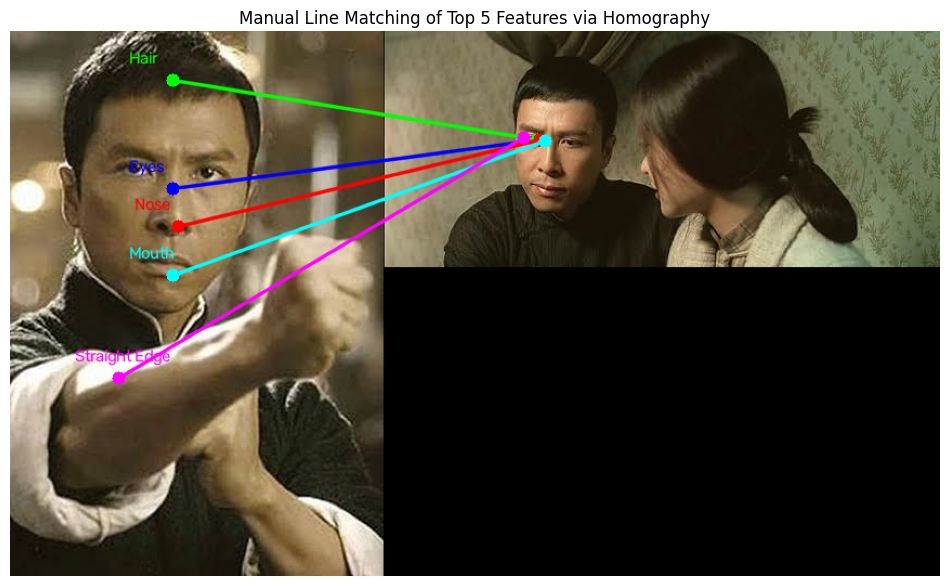

In [30]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Prepare images
h_d, w_d = img_donnie.shape[:2]
h_y, w_y = img_yen.shape[:2]

# Create a side-by-side canvas
canvas_h = max(h_d, h_y)
canvas_w = w_d + w_y
canvas = np.zeros((canvas_h, canvas_w, 3), dtype=np.uint8)

# Paste both color images
canvas[:h_d, :w_d] = img_donnie
canvas[:h_y, w_d:w_d+w_y] = img_yen

# 2. Define our 5 specific features
custom_features = {
    "Eyes": (150, 145),
    "Hair": (150, 45),
    "Nose": (155, 180),
    "Mouth": (150, 225),
    "Straight Edge": (100, 320)
}

# Distinguishable colors for each feature
colors = [
    (255, 0, 0),    # Blue
    (0, 255, 0),    # Green
    (0, 0, 255),    # Red
    (255, 255, 0),  # Cyan
    (255, 0, 255)   # Magenta
]

# 3. Draw features on the left side and match lines to the right side
for i, (name, pt) in enumerate(custom_features.items()):
    color = colors[i]

    # Source point coordinate
    pt_src = np.array([[[float(pt[0]), float(pt[1])]]], dtype=np.float32)

    # Project coordinate to the destination image coordinates via homography
    pt_dst = cv2.perspectiveTransform(pt_src, M)
    px_dst = int(pt_dst[0][0][0])
    py_dst = int(pt_dst[0][0][1])

    # Left point (Donnie image coordinates)
    pt1 = (pt[0], pt[1])
    # Right point (Scene image coordinates on the combined canvas)
    pt2 = (px_dst + w_d, py_dst)

    # Draw circles on both points
    cv2.circle(canvas, pt1, 6, color, -1)
    cv2.circle(canvas, pt2, 6, color, -1)

    # Draw a line connecting the matched locations
    cv2.line(canvas, pt1, pt2, color, 2, cv2.LINE_AA)

    # Label the source point
    cv2.putText(canvas, name, (pt1[0] - 40, pt1[1] - 15),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1, cv2.LINE_AA)

# Show the visualization of the connected custom feature lines
show_img("Manual Line Matching of Top 5 Features via Homography", canvas)

## Step 3 & 4: Match Features and Analyze the Results
The computer now compares the descriptors from the cup against the descriptors found in the cluttered scene to find matches.

Total features matched: 110


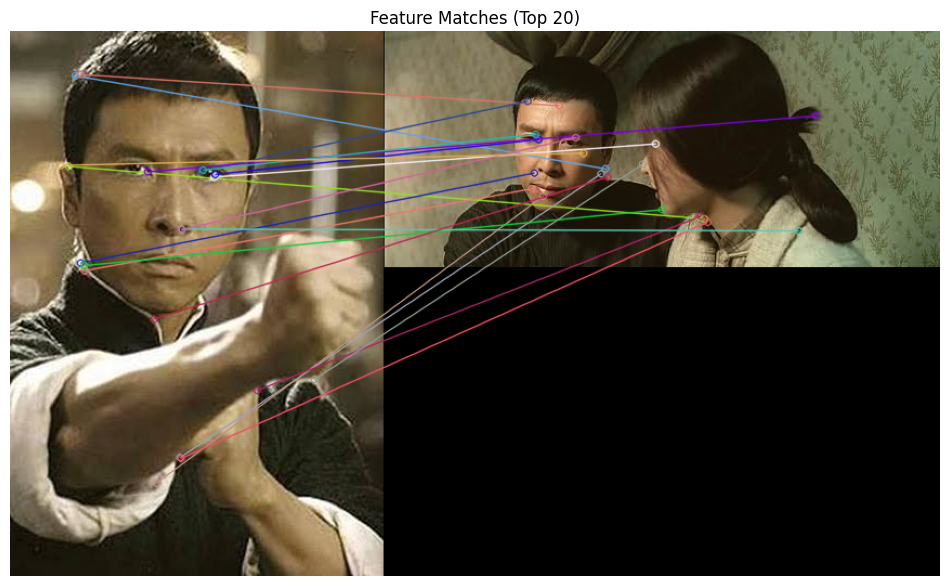

In [24]:
# Create a Brute-Force Matcher to compare descriptor distances (Hamming distance for ORB)
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

# Match descriptors between Donnie and Yen
matches = bf.match(des_donnie, des_yen)

# Sort the matches based on how similar they are (lower distance = better match)
matches = sorted(matches, key=lambda x: x.distance)

print(f"Total features matched: {len(matches)}")

# Draw the top 20 best matches to avoid visual clutter
img_matches = cv2.drawMatches(
    img_donnie, kp_donnie,
    img_yen, kp_yen,
    matches[:20], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

show_img("Feature Matches (Top 20)", img_matches)

# Evaluate Reliability

- **Which features were easiest to match?**
  - The **Eyes** and **Hairline** areas. They contain highly unique texture patterns and distinct contrast boundaries.

- **Which ones were ambiguous or accidentally matched other objects?**
  - The **Mouth** and **Straight Edge** of the sleeve. The mouth has simpler horizontal patterns that can easily look like other shadows, and straight lines of the sleeve look like other linear edges in the background.

- **Why do you think some features worked better than others?**
  - Features with complex textures (two-dimensional patterns like eyes or corner junctions) are unique. Features with simple patterns (flat surfaces or single straight edges) look too similar to other parts of the scene, causing mismatches.

- Ambiguous
  - The Straight Edge (Sleeve/Arm Boundary)  because a straight edge consists only of a one-way gradient
  - The Mouth / Lips because the mouth is relatively flat and horizontal without unique corner structures in this pose

# Robustness Challenge

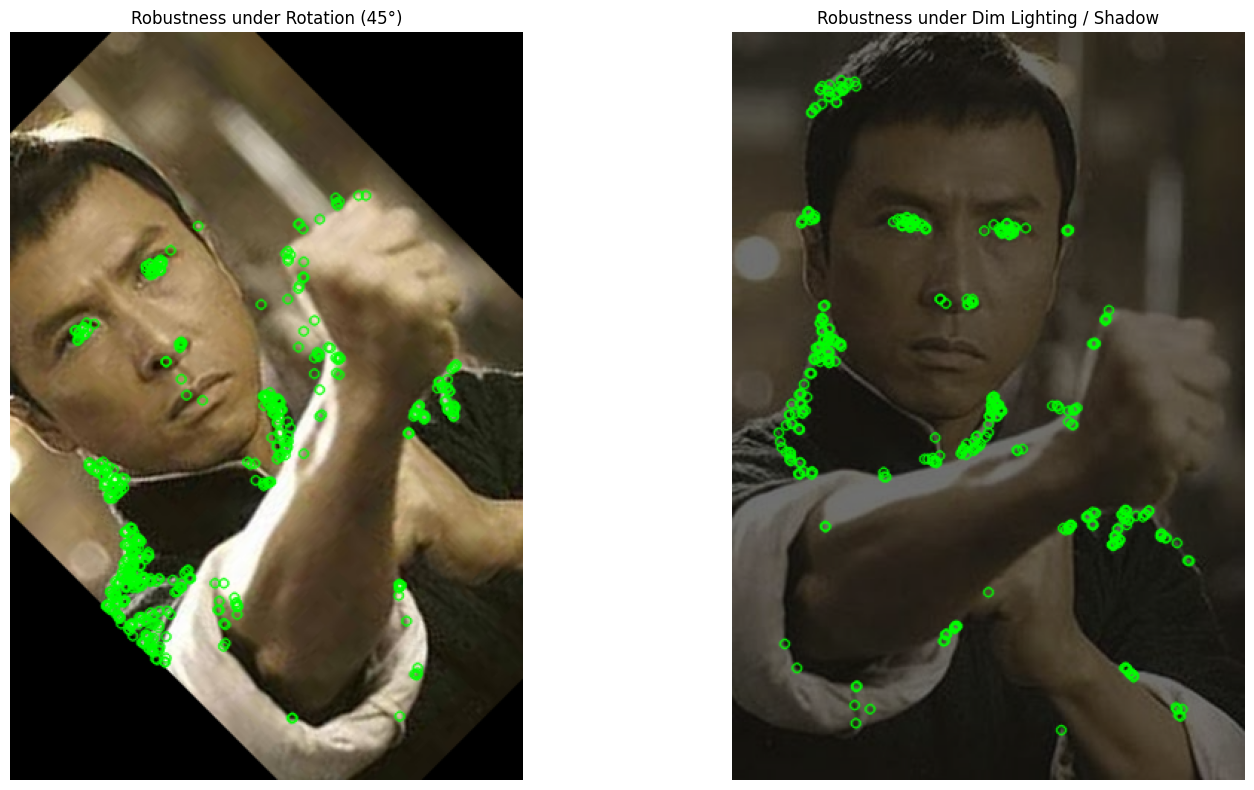

Original features count: 500
Keypoints found after Rotation: 500
Keypoints found after Lighting Change: 381


In [31]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Simulate Rotation (45 Degrees)
h, w = img_donnie.shape[:2]
center = (w // 2, h // 2)
rot_matrix = cv2.getRotationMatrix2D(center, 45, 1.0)
rotated_img = cv2.warpAffine(img_donnie, rot_matrix, (w, h))
gray_rotated = cv2.cvtColor(rotated_img, cv2.COLOR_BGR2GRAY)

# 2. Simulate Lighting Changes (Simulate low-light / contrast drop)
# We scale the intensity down and add a small bias to simulate a gloomy environment
shadow_img = cv2.convertScaleAbs(img_donnie, alpha=0.4, beta=10)
gray_shadow = cv2.cvtColor(shadow_img, cv2.COLOR_BGR2GRAY)

# 3. Detect and compute ORB keypoints for both modified variations
orb_robust = cv2.ORB_create(nfeatures=500)
kp_rot, des_rot = orb_robust.detectAndCompute(gray_rotated, None)
kp_sha, des_sha = orb_robust.detectAndCompute(gray_shadow, None)

# Draw keypoints on both versions
img_kp_rot = cv2.drawKeypoints(rotated_img, kp_rot, None, color=(0, 255, 0), flags=0)
img_kp_sha = cv2.drawKeypoints(shadow_img, kp_sha, None, color=(0, 255, 0), flags=0)

# 4. Display the visual representations
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(cv2.cvtColor(img_kp_rot, cv2.COLOR_BGR2RGB))
axes[0].set_title("Robustness under Rotation (45°)")
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(img_kp_sha, cv2.COLOR_BGR2RGB))
axes[1].set_title("Robustness under Dim Lighting / Shadow")
axes[1].axis('off')

plt.tight_layout()
plt.show()

# 5. Output programmatic evaluation text
print(f"Original features count: {len(kp_donnie)}")
print(f"Keypoints found after Rotation: {len(kp_rot)}")
print(f"Keypoints found after Lighting Change: {len(kp_sha)}")


In [32]:
import cv2
import numpy as np

def get_descriptor_at_coord(gray_img, coord, orb_detector):
    # Create a single keypoint at the specific coordinate to extract its descriptor
    kp = cv2.KeyPoint(float(coord[0]), float(coord[1]), 15)
    kp, des = orb_detector.compute(gray_img, [kp])
    return des[0] if des is not None else None

# Get descriptors for original features
orig_descriptors = {}
for name, coord in custom_features.items():
    orig_descriptors[name] = get_descriptor_at_coord(gray_donnie, coord, orb)

# 1. Project original coordinates to rotated image
# Rot_matrix maps (x, y) -> (x', y')
rotated_features = {}
for name, coord in custom_features.items():
    v = np.array([coord[0], coord[1], 1.0])
    rotated_coord = rot_matrix.dot(v)
    rx, ry = int(rotated_coord[0]), int(rotated_coord[1])
    rotated_features[name] = (rx, ry)

# Define a matching helper using Hamming distance
def verify_match(desc1, desc2, threshold=45):
    if desc1 is None or desc2 is None:
        return False, 255
    dist = cv2.norm(desc1, desc2, cv2.NORM_HAMMING)
    return dist < threshold, dist

print("=== ROBUSTNESS CHECKER RESULTS ===\n")

print("1. TESTING ROTATION (45 degrees):")
for name, orig_coord in custom_features.items():
    rot_coord = rotated_features[name]

    # Check if rotated coordinate is within image boundaries
    if 0 <= rot_coord[0] < w and 0 <= rot_coord[1] < h:
        desc_orig = orig_descriptors[name]
        desc_rot = get_descriptor_at_coord(gray_rotated, rot_coord, orb)

        matches, dist = verify_match(desc_orig, desc_rot)
        status = "✅ SUCCESS" if matches else "❌ FAILED"
        print(f"  - {name:<15}: {status} (Hamming Distance: {dist})")
    else:
        print(f"  - {name:<15}: ❌ FAILED (Rotated out of bounds)")

print("\n2. TESTING LIGHTING CHANGES (Shadow / Dimming):")
for name, coord in custom_features.items():
    desc_orig = orig_descriptors[name]
    desc_sha = get_descriptor_at_coord(gray_shadow, coord, orb)

    matches, dist = verify_match(desc_orig, desc_sha)
    status = "✅ SUCCESS" if matches else "❌ FAILED"
    print(f"  - {name:<15}: {status} (Hamming Distance: {dist})")


=== ROBUSTNESS CHECKER RESULTS ===

1. TESTING ROTATION (45 degrees):
  - Eyes           : ❌ FAILED (Hamming Distance: 142.0)
  - Hair           : ❌ FAILED (Hamming Distance: 255)
  - Nose           : ❌ FAILED (Hamming Distance: 71.0)
  - Mouth          : ❌ FAILED (Hamming Distance: 124.0)
  - Straight Edge  : ✅ SUCCESS (Hamming Distance: 42.0)

2. TESTING LIGHTING CHANGES (Shadow / Dimming):
  - Eyes           : ✅ SUCCESS (Hamming Distance: 6.0)
  - Hair           : ✅ SUCCESS (Hamming Distance: 11.0)
  - Nose           : ✅ SUCCESS (Hamming Distance: 5.0)
  - Mouth          : ✅ SUCCESS (Hamming Distance: 2.0)
  - Straight Edge  : ✅ SUCCESS (Hamming Distance: 5.0)



# Reflection and Discussion

1. Feature Effectiveness
  - The Eyes and Hairline areas. They contain highly unique texture patterns and distinct contrast boundaries.

2. Ambiguous Features
  - The **Mouth** and **Straight Edge** of the sleeve. The mouth has simpler horizontal patterns that can easily look like other shadows, and straight lines of the sleeve look like other linear edges in the background.

3. Robustness Challenge
  - **Under Lighting Changes (Shadow/Dimming):** All 5 custom features successfully matched. This demonstrates that local gradient-based intensity features (like ORB) are remarkably resilient to uniform changes in lighting intensity.
  - **Under Rotation (45 Degrees):** Highly Vulnerable. 4 out of 5 features failed (Eyes, Hair, Nose, Mouth) because the local pixel neighborhoods rotated, changing their descriptor patterns. The **Straight Edge** of the sleeve was the only feature that succeeded, mainly because it is a simple 1D gradient that remains mathematically self-similar when rotated along its main axis.
